In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
df = pd.read_excel('/content/Sales_Project_Dataset.xlsx')
df.head()


,Order_ID,Product,Category,Quantity,Unit_Price,Sales,Profit,Region,Payment_Method,Order_Date
0,ORD-1000,Keyboard,Accessories,7,910,6370,2717.61,West,Card,2023-03-13
1,ORD-1001,Keyboard,Accessories,5,171,855,374.15,North,Card,2023-11-27
2,ORD-1002,Phone,Electronics,8,1446,11568,3002.52,East,Transfer,2023-06-01
3,ORD-1003,Laptop,Electronics,3,1382,4146,464.50,West,Transfer,2023-10-21
4,ORD-1004,Headphones,Accessories,2,1265,2530,260.88,West,Card,2023-06-10


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 305 entries, 0 to 304
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        305 non-null    object        
 1   Product         305 non-null    object        
 2   Category        305 non-null    object        
 3   Quantity        305 non-null    int64         
 4   Unit_Price      305 non-null    int64         
 5   Sales           305 non-null    int64         
 6   Profit          305 non-null    float64       
 7   Region          295 non-null    object        
 8   Payment_Method  295 non-null    object        
 9   Order_Date      305 non-null    datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(5)
memory usage: 24.0+ KB


In [ ]:
df.columns

Index(['Order_ID', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Sales',
       'Profit', 'Region', 'Payment_Method', 'Order_Date'],
      dtype='object')

In [ ]:
df.columns = df.columns.str.strip().str.lower()

In [ ]:
def data_check(dataframe):
  report = pd.DataFrame({
      'Dtypes' : dataframe.dtypes,
  'Null' : dataframe.isnull().sum(),
      'Null_pct' :(dataframe.isnull().sum()/len(dataframe)*100).round(2),
      'Unique' : dataframe.nunique()
})
  return report.sort_values('Null_pct', ascending=False)

health = data_check(df)
print(f'\n💎 DATA_CHECK {df.shape[0]:,} Rows x {df.shape[1]} Columns')
display(health)


💎 DATA_CHECK 300 Rows x 10 Columns


,Dtypes,Null,Null_pct,Unique
region,object,10,3.33,4
payment_method,object,10,3.33,3
product,object,0,0.00,7
order_id,object,0,0.00,300
category,object,0,0.00,2
quantity,int64,0,0.00,9
sales,int64,0,0.00,288
unit_price,int64,0,0.00,272
profit,float64,0,0.00,300
order_date,datetime64[ns],0,0.00,202


In [ ]:
df.duplicated().sum()

np.int64(5)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df['region'] = df['region'].fillna('Unknown')
df['region']

,region
0,West
1,North
2,East
3,West
4,West
...,...
295,West
296,North
297,West
298,South


In [ ]:
df['payment_method'] = df['payment_method'].fillna(df['payment_method'].mode()[0])
df['payment_method'].isnull().sum()

np.int64(0)

In [ ]:
df.head()

,order_id,product,category,quantity,unit_price,sales,profit,region,payment_method,order_date
0,ORD-1000,Keyboard,Accessories,7,910,6370,2717.61,West,Card,2023-03-13
1,ORD-1001,Keyboard,Accessories,5,171,855,374.15,North,Card,2023-11-27
2,ORD-1002,Phone,Electronics,8,1446,11568,3002.52,East,Transfer,2023-06-01
3,ORD-1003,Laptop,Electronics,3,1382,4146,464.50,West,Transfer,2023-10-21
4,ORD-1004,Headphones,Accessories,2,1265,2530,260.88,West,Card,2023-06-10


In [ ]:
df['order_date'] = pd.to_datetime(df['order_date'])
df['order_date'].dtypes

dtype('<M8[ns]')

In [ ]:
df.dtypes

,0
order_id,object
product,object
category,object
quantity,int64
unit_price,int64
sales,int64
profit,float64
region,object
payment_method,object
order_date,datetime64[ns]


In [ ]:
df.head()

,order_id,product,category,quantity,unit_price,sales,profit,region,payment_method,order_date
0,ORD-1000,Keyboard,Accessories,7,910,6370,2717.61,West,Card,2023-03-13
1,ORD-1001,Keyboard,Accessories,5,171,855,374.15,North,Card,2023-11-27
2,ORD-1002,Phone,Electronics,8,1446,11568,3002.52,East,Transfer,2023-06-01
3,ORD-1003,Laptop,Electronics,3,1382,4146,464.50,West,Transfer,2023-10-21
4,ORD-1004,Headphones,Accessories,2,1265,2530,260.88,West,Card,2023-06-10


In [ ]:
df['day'] = df['order_date'].dt.day
df.head()

,order_id,product,category,quantity,unit_price,sales,profit,region,payment_method,order_date,day
0,ORD-1000,Keyboard,Accessories,7,910,6370,2717.61,West,Card,2023-03-13,13
1,ORD-1001,Keyboard,Accessories,5,171,855,374.15,North,Card,2023-11-27,27
2,ORD-1002,Phone,Electronics,8,1446,11568,3002.52,East,Transfer,2023-06-01,1
3,ORD-1003,Laptop,Electronics,3,1382,4146,464.50,West,Transfer,2023-10-21,21
4,ORD-1004,Headphones,Accessories,2,1265,2530,260.88,West,Card,2023-06-10,10


In [ ]:
df['month'] = df['order_date'].dt.month
df['year'] = df['order_date'].dt.year
df.head()

,order_id,product,category,quantity,unit_price,sales,profit,region,payment_method,order_date,day,month,year
0,ORD-1000,Keyboard,Accessories,7,910,6370,2717.61,West,Card,2023-03-13,13,3,2023
1,ORD-1001,Keyboard,Accessories,5,171,855,374.15,North,Card,2023-11-27,27,11,2023
2,ORD-1002,Phone,Electronics,8,1446,11568,3002.52,East,Transfer,2023-06-01,1,6,2023
3,ORD-1003,Laptop,Electronics,3,1382,4146,464.50,West,Transfer,2023-10-21,21,10,2023
4,ORD-1004,Headphones,Accessories,2,1265,2530,260.88,West,Card,2023-06-10,10,6,2023


In [ ]:
df['profit_margin'] = ((df['profit']/df['sales'])*100).round(2)

In [ ]:
df.head()

,order_id,product,category,quantity,unit_price,sales,profit,region,payment_method,order_date,day,month,year,profit_margin
0,ORD-1000,Keyboard,Accessories,7,910,6370,2717.61,West,Card,2023-03-13,13,3,2023,42.66
1,ORD-1001,Keyboard,Accessories,5,171,855,374.15,North,Card,2023-11-27,27,11,2023,43.76
2,ORD-1002,Phone,Electronics,8,1446,11568,3002.52,East,Transfer,2023-06-01,1,6,2023,25.96
3,ORD-1003,Laptop,Electronics,3,1382,4146,464.50,West,Transfer,2023-10-21,21,10,2023,11.20
4,ORD-1004,Headphones,Accessories,2,1265,2530,260.88,West,Card,2023-06-10,10,6,2023,10.31


# sales by region


In [ ]:
sales = df.groupby(['region'])['sal'].sum()
sales

,sales
region,
East,283083
North,277692
South,279651
Unknown,56240
West,293277


#Profit by category



In [ ]:
Profit_by_cat = df.groupby(['category'])['profit'].sum()
Profit_by_cat

,profit
category,
Accessories,168938.36
Electronics,182535.92


#Monthly sales

In [ ]:
Monthly_sales = df.groupby(['month'])['sales'].sum()
Monthly_sales

,sales
month,
1,93195
2,113310
3,89541
4,105935
5,94977
6,121350
7,68552
8,107781
9,91142


#visualization

[Text(0, 0, '283083'),
 Text(0, 0, '277692'),
 Text(0, 0, '279651'),
 Text(0, 0, '56240'),
 Text(0, 0, '293277')]

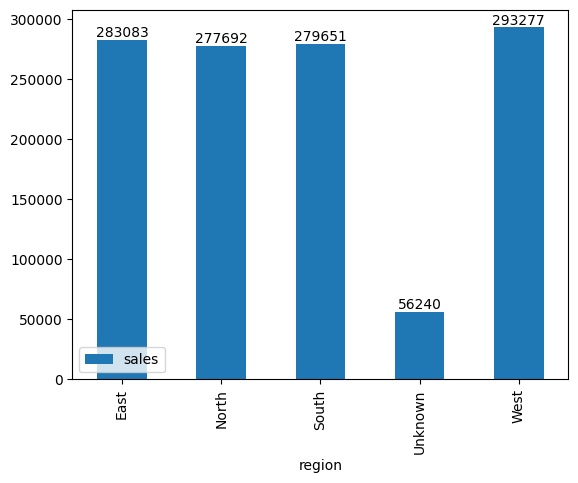

In [ ]:
vis = sales.plot(kind='bar',legend=True)
vis.bar_label(vis.containers[0])

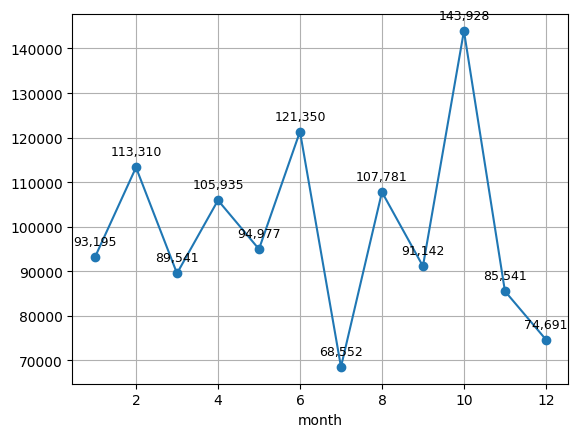

In [ ]:
line = Monthly_sales.plot(kind='line', marker='o', grid=True)
for x, y in zip(Monthly_sales.index, Monthly_sales.values):
    line.text(x, y + 2000, f'{y:,}', ha='center', va='bottom', fontsize=9)

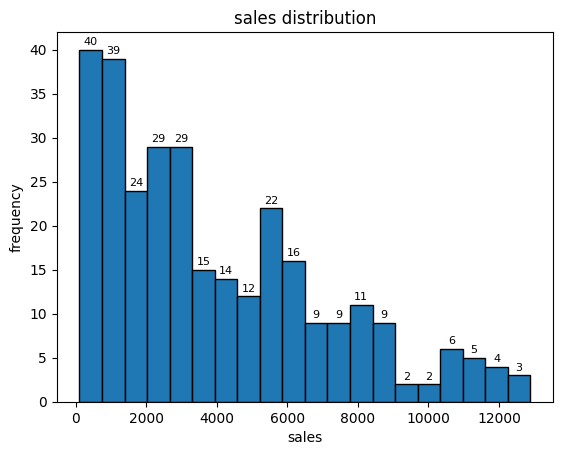

In [ ]:
ax = df['sales'].plot(kind='hist', bins=20, edgecolor='black')
for container in ax.containers:
    ax.bar_label(container, padding=2, fontsize=8)
plt.title('sales distribution')
plt.xlabel('sales')
plt.ylabel('frequency')
plt.show()

#Profit distribution


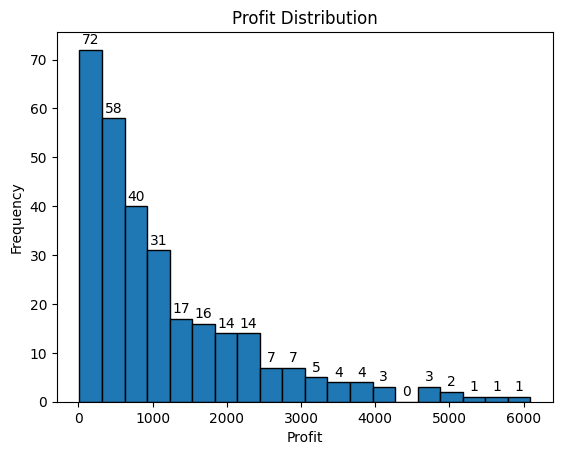

In [ ]:
ax = df['profit'].plot(kind='hist', bins=20, edgecolor='black')

for container in ax.containers:
    ax.bar_label(container, padding=2, fontsize=10)

plt.title('Profit Distribution')
plt.xlabel('Profit')
plt.ylabel('Frequency')
plt.show()

In [ ]:
Top_selling = df.groupby(['product'])['quantity'].sum().sort_values(ascending=False)
Top_selling

,quantity
product,
Keyboard,254
Tablet,222
Mouse,208
Monitor,203
Laptop,195
Headphones,194
Phone,192


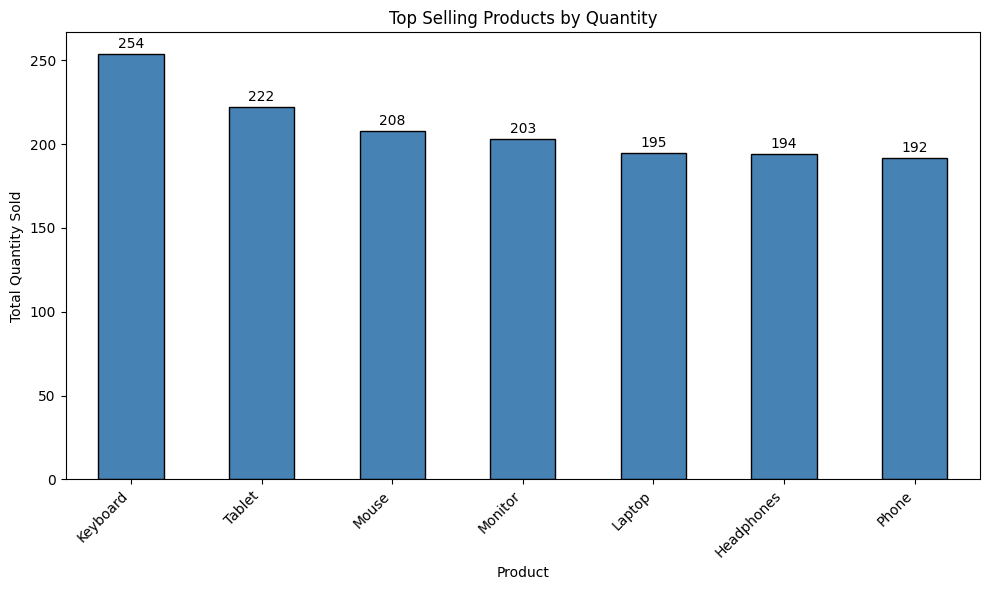

In [ ]:
ax = Top_selling.plot(kind='bar', figsize=(10, 6), edgecolor='black', color='steelblue')

for container in ax.containers:
    ax.bar_label(container, padding=2, fontsize=10)

plt.title('Top Selling Products by Quantity')
plt.xlabel('Product')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#Profit by region

<Axes: ylabel='True'>

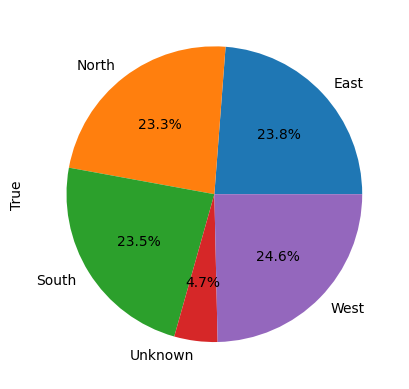

In [ ]:
sales.plot(kind='pie', label=True, autopct='%1.1f%%')

In [ ]:
df.to_excel("cleaned_data.xlsx", index=False)
